# Mini Project: Uber Fare Prediction

## Problem statement

Predict the fare for a ride using pickup and drop-off locations, passenger count, and pickup time. This mini project follows the requested workflow: preprocess the dataset, identify outliers, inspect correlations, train Linear Regression and Random Forest Regression, then compare R², RMSE, and MAE.

## Dataset

Use the uber.csv file from the Kaggle Uber Fares Dataset. Place it at Data/uber.csv; download instructions are in the repository README.

The data is a historical New York City fare sample. The cleaning step uses a broad NYC-area coordinate box to remove corrupted or geographically implausible coordinates. IQR outliers are reported, and plausible high fares are retained so the analysis does not discard every long trip.

In [1]:
%matplotlib inline

from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
DATA_PATH = Path("Data/uber.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Place the Kaggle uber.csv file at Data/uber.csv (see the repository README)."
    )

## 1. Load and inspect the data

Review the columns, missing values, duplicate count, and basic fare statistics. The source file also includes an index-like column and a unique ride key; these are not model features.

In [2]:
raw = pd.read_csv(DATA_PATH)
print("Raw dataset shape:", raw.shape)
print("Columns:", raw.columns.tolist())
print("Missing values by column:")
print(raw.isna().sum().to_string())
print("Duplicate rows:", int(raw.duplicated().sum()))
display(raw.head())

Raw dataset shape: (200000, 9)
Columns: ['Unnamed: 0', 'key', 'fare_amount', 'pickup_datetime', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'passenger_count']
Missing values by column:
Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
Duplicate rows: 0


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


## 2. Pre-process the dataset

Convert fields to numeric or datetime types, remove identifier columns, and filter invalid fares, out-of-range coordinates, and implausible passenger counts. The fare ceiling of 250 USD removes extreme corrupted values; the later IQR analysis separately identifies statistical fare outliers.

In [3]:
required_columns = [
    "fare_amount", "pickup_datetime", "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude", "passenger_count",
]
missing_columns = sorted(set(required_columns) - set(raw.columns))
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {missing_columns}")

data = raw[required_columns].copy()
numeric_columns = [
    "fare_amount", "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude", "passenger_count",
]
for column in numeric_columns:
    data[column] = pd.to_numeric(data[column], errors="coerce")
data["pickup_datetime"] = pd.to_datetime(data["pickup_datetime"], errors="coerce", utc=True)
data = data.replace([np.inf, -np.inf], np.nan).dropna(subset=required_columns)
data = data.drop_duplicates().copy()

nyc_area = (
    data["pickup_longitude"].between(-75.5, -72.0)
    & data["dropoff_longitude"].between(-75.5, -72.0)
    & data["pickup_latitude"].between(40.0, 42.0)
    & data["dropoff_latitude"].between(40.0, 42.0)
)
valid_fare = data["fare_amount"].between(0.01, 250.00)
valid_passengers = data["passenger_count"].between(1, 6)
valid_rows = nyc_area & valid_fare & valid_passengers

print("Rows after removing missing/duplicate records:", len(data))
print("Rows removed by fare, NYC-coordinate, or passenger rules:", int((~valid_rows).sum()))
data = data.loc[valid_rows].copy().reset_index(drop=True)
print("Rows retained for analysis:", len(data))
display(data[numeric_columns].describe().round(2))

Rows after removing missing/duplicate records: 199999
Rows removed by fare, NYC-coordinate, or passenger rules: 4891
Rows retained for analysis: 195108


,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,195108.00,195108.00,195108.00,195108.00,195108.00,195108.00
mean,11.35,-73.98,40.75,-73.97,40.75,1.69
std,9.74,0.04,0.03,0.04,0.03,1.31
min,0.01,-75.42,40.00,-75.42,40.01,1.00
25%,6.00,-73.99,40.74,-73.99,40.74,1.00
50%,8.50,-73.98,40.75,-73.98,40.75,1.00
75%,12.50,-73.97,40.77,-73.97,40.77,2.00
max,230.00,-72.75,41.37,-72.76,41.50,6.00


## 3. Identify fare outliers

Use the 1.5 × IQR rule on valid fares. The count is reported and visualized. A fare beyond the IQR fence is unusual relative to this sample but may still represent a legitimate long ride, so such values are retained for the model.

Q1 fare: 6.00 USD
Q3 fare: 12.50 USD
IQR fences: -3.75 to 22.25 USD
Fare outliers: 16,713 (8.57% of cleaned rows)
IQR outliers are retained after the separate validity checks.


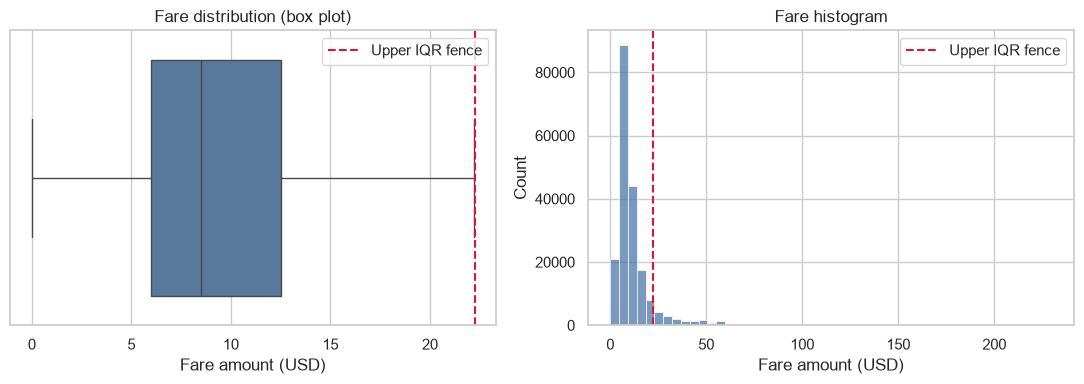

In [4]:
q1 = data["fare_amount"].quantile(0.25)
q3 = data["fare_amount"].quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
fare_outliers = (data["fare_amount"] < lower_fence) | (data["fare_amount"] > upper_fence)

print(f"Q1 fare: {q1:.2f} USD")
print(f"Q3 fare: {q3:.2f} USD")
print(f"IQR fences: {lower_fence:.2f} to {upper_fence:.2f} USD")
print(f"Fare outliers: {int(fare_outliers.sum()):,} ({fare_outliers.mean():.2%} of cleaned rows)")
print("IQR outliers are retained after the separate validity checks.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(x=data["fare_amount"], showfliers=False, color="#4C78A8", ax=axes[0])
axes[0].axvline(upper_fence, color="crimson", linestyle="--", label="Upper IQR fence")
axes[0].set_title("Fare distribution (box plot)")
axes[0].set_xlabel("Fare amount (USD)")
axes[0].legend()
sns.histplot(data["fare_amount"], bins=50, color="#4C78A8", ax=axes[1])
axes[1].axvline(upper_fence, color="crimson", linestyle="--", label="Upper IQR fence")
axes[1].set_title("Fare histogram")
axes[1].set_xlabel("Fare amount (USD)")
axes[1].legend()
plt.tight_layout()
plt.show()

## 4. Engineer features and check correlation

Calculate great-circle distance between pickup and drop-off coordinates with the Haversine formula. Encode pickup hour, weekday, and month cyclically so nearby times remain numerically close. The correlation table and heatmap show Pearson correlations with fare and among the numeric variables.

Correlation with fare_amount:
distance_km          0.823
pickup_longitude     0.361
dropoff_longitude    0.265
pickup_year          0.120
pickup_month         0.024
passenger_count      0.011
pickup_weekday       0.006
pickup_hour         -0.021
dropoff_latitude    -0.152
pickup_latitude     -0.186


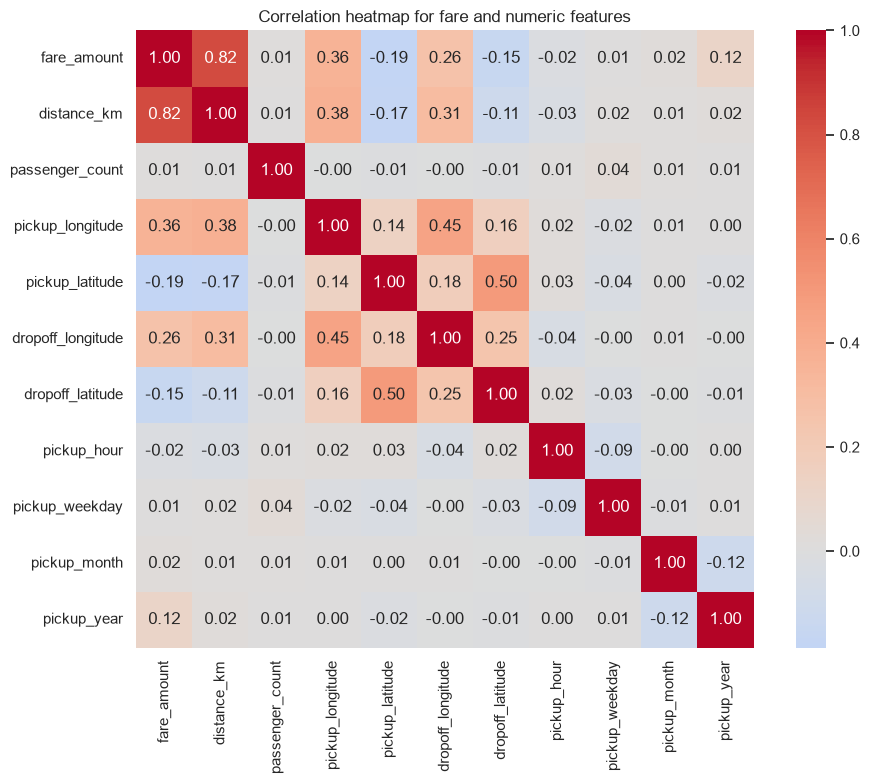

In [5]:
lat1 = np.radians(data["pickup_latitude"].to_numpy())
lat2 = np.radians(data["dropoff_latitude"].to_numpy())
lon1 = np.radians(data["pickup_longitude"].to_numpy())
lon2 = np.radians(data["dropoff_longitude"].to_numpy())
a = (
    np.sin((lat2 - lat1) / 2) ** 2
    + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
)
data["distance_km"] = 6371.0 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

pickup_time = data["pickup_datetime"]
data["pickup_hour"] = pickup_time.dt.hour.astype("int8")
data["pickup_weekday"] = pickup_time.dt.dayofweek.astype("int8")
data["pickup_month"] = pickup_time.dt.month.astype("int8")
data["pickup_year"] = pickup_time.dt.year.astype("int16")

data["hour_sin"] = np.sin(2 * np.pi * data["pickup_hour"] / 24)
data["hour_cos"] = np.cos(2 * np.pi * data["pickup_hour"] / 24)
data["weekday_sin"] = np.sin(2 * np.pi * data["pickup_weekday"] / 7)
data["weekday_cos"] = np.cos(2 * np.pi * data["pickup_weekday"] / 7)
data["month_sin"] = np.sin(2 * np.pi * (data["pickup_month"] - 1) / 12)
data["month_cos"] = np.cos(2 * np.pi * (data["pickup_month"] - 1) / 12)

correlation_columns = [
    "fare_amount", "distance_km", "passenger_count",
    "pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude",
    "pickup_hour", "pickup_weekday", "pickup_month", "pickup_year",
]
corr = data[correlation_columns].corr(numeric_only=True)
print("Correlation with fare_amount:")
print(corr["fare_amount"].drop("fare_amount").sort_values(ascending=False).round(3).to_string())

plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", square=True)
plt.title("Correlation heatmap for fare and numeric features")
plt.tight_layout()
plt.show()

## 5. Train Linear Regression and Random Forest Regression

Use a reproducible random 80/20 train-test split. The linear model standardizes features; scaling is not required by the tree model. A random split is used for this practical comparison, so the scores are an IID benchmark rather than a strict future-date forecast.

In [6]:
feature_columns = [
    "pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude",
    "passenger_count", "distance_km",
    "hour_sin", "hour_cos", "weekday_sin", "weekday_cos",
    "month_sin", "month_cos", "pickup_year",
]
X = data[feature_columns]
y = data["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Model features:", len(feature_columns))

linear_model = make_pipeline(StandardScaler(), LinearRegression())
forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=18,
    min_samples_leaf=2,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

linear_model.fit(X_train, y_train)
forest_model.fit(X_train, y_train)
linear_predictions = linear_model.predict(X_test)
forest_predictions = forest_model.predict(X_test)
print("Both regression models are trained.")

Training rows: 156086
Test rows: 39022
Model features: 13


Both regression models are trained.


## 6. Evaluate and compare the models

R² measures variance explained, while RMSE and MAE measure prediction error in USD. Lower RMSE/MAE and higher R² indicate better test-set performance.

In [7]:
def regression_metrics(actual, predicted):
    return {
        "R²": r2_score(actual, predicted),
        "RMSE (USD)": np.sqrt(mean_squared_error(actual, predicted)),
        "MAE (USD)": mean_absolute_error(actual, predicted),
    }

results = pd.DataFrame(
    {
        "Linear Regression": regression_metrics(y_test, linear_predictions),
        "Random Forest": regression_metrics(y_test, forest_predictions),
    }
).T
display(results.round(4))

best_rmse = results["RMSE (USD)"].idxmin()
print("Lower test RMSE:", best_rmse)
print(
    f"RMSE = {results.loc[best_rmse, 'RMSE (USD)']:.2f} USD; "
    f"MAE = {results.loc[best_rmse, 'MAE (USD)']:.2f} USD; "
    f"R² = {results.loc[best_rmse, 'R²']:.4f}"
)

,R²,RMSE (USD),MAE (USD)
Linear Regression,0.6904,5.5376,2.3984
Random Forest,0.8336,4.0603,1.8388


Lower test RMSE: Random Forest
RMSE = 4.06 USD; MAE = 1.84 USD; R² = 0.8336


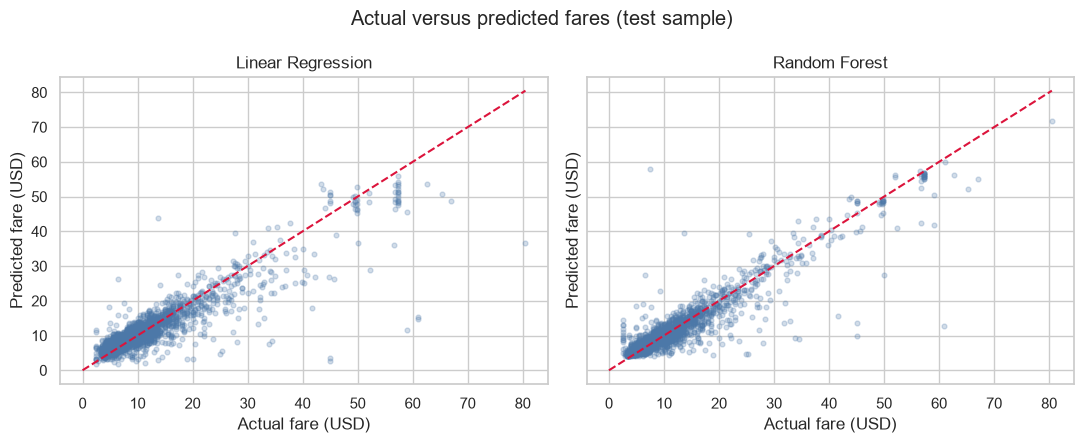

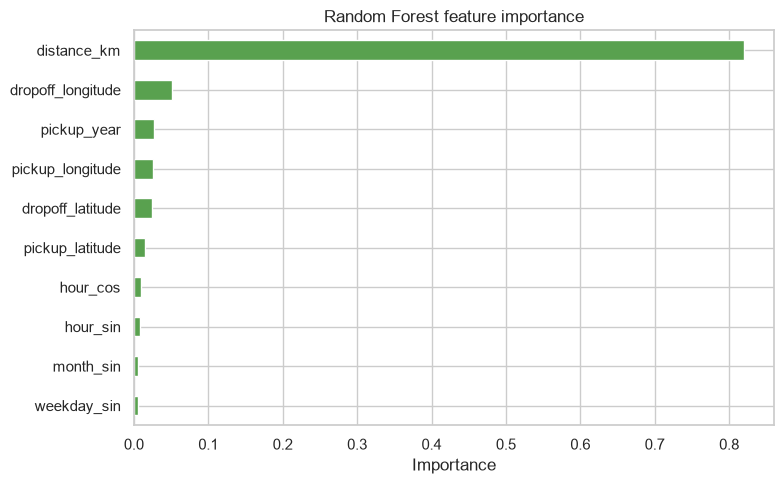

In [8]:
sample_size = min(2500, len(y_test))
sample_positions = np.random.default_rng(RANDOM_STATE).choice(
    len(y_test), size=sample_size, replace=False
)
actual_sample = y_test.iloc[sample_positions].to_numpy()
linear_sample = linear_predictions[sample_positions]
forest_sample = forest_predictions[sample_positions]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for ax, model_name, predicted in [
    (axes[0], "Linear Regression", linear_sample),
    (axes[1], "Random Forest", forest_sample),
]:
    ax.scatter(actual_sample, predicted, alpha=0.25, s=12, color="#4C78A8")
    limit = max(float(actual_sample.max()), float(predicted.max()))
    ax.plot([0, limit], [0, limit], linestyle="--", color="crimson")
    ax.set_title(model_name)
    ax.set_xlabel("Actual fare (USD)")
    ax.set_ylabel("Predicted fare (USD)")
fig.suptitle("Actual versus predicted fares (test sample)")
plt.tight_layout()
plt.show()

importance = pd.Series(forest_model.feature_importances_, index=feature_columns)
importance.nlargest(10).sort_values().plot(kind="barh", figsize=(8, 5), color="#59A14F")
plt.title("Random Forest feature importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 7. Conclusion

The comparison table gives the final model scores. Discuss which model has the lower RMSE and MAE and the higher R². Distance and route coordinates are central predictors; the results describe the cleaned historical sample and should not be treated as a live fare quote.

In [9]:
print("Conclusion based on the test-set comparison:")
print(f"- Best R²: {results['R²'].idxmax()}")
print(f"- Lowest RMSE: {results['RMSE (USD)'].idxmin()}")
print(f"- Lowest MAE: {results['MAE (USD)'].idxmin()}")
print(
    f"- IQR-flagged fares retained for modeling: {int(fare_outliers.sum()):,} "
    f"out of {len(data):,} cleaned rides."
)

Conclusion based on the test-set comparison:
- Best R²: Random Forest
- Lowest RMSE: Random Forest
- Lowest MAE: Random Forest
- IQR-flagged fares retained for modeling: 16,713 out of 195,108 cleaned rides.
